# Solar India · 02 Modelling
Exploratory analysis, PCA, regression (how much solar energy?) and classification (poor / average / good day),
then one final test on the most recent 12 months and export for the app. Input: `data/solar.csv`. Output: `models/`.

In [30]:
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import (mean_squared_error, mean_absolute_error, r2_score, accuracy_score,
                             precision_score, recall_score, f1_score, confusion_matrix, classification_report)

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.regularizers import l2

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR, MODEL_DIR = ROOT / "data", ROOT / "models"
MODEL_DIR.mkdir(exist_ok=True)
np.random.seed(42)
tf.random.set_seed(42)

data = pd.read_csv(DATA_DIR / "solar.csv", parse_dates=["date"])
train = (data["split"] == "train").values
val = (data["split"] == "val").values
test = (data["split"] == "test").values
print(data.shape, "| train / val / test:", train.sum(), val.sum(), test.sum())

(93104, 23) | train / val / test: 77044 8030 8030


In [31]:
data.head()

,date,solar,clear_sky,cloud,temp,temp_max,temp_min,dew_point,humidity,specific_humidity,...,city,lat,lon,region,clearness,day_type,month,day_of_year,year,split
0,2015-01-01,2.5447,3.8890,54.13,20.00,27.69,15.23,12.29,63.15,8.88,...,Ahmedabad,23.02,72.57,West,0.654333,average,1,1,2015,train
1,2015-01-02,3.4606,3.8167,24.52,19.02,26.80,12.19,10.99,62.48,8.13,...,Ahmedabad,23.02,72.57,West,0.906700,good,1,2,2015,train
2,2015-01-03,3.7430,3.8952,9.82,20.03,28.07,12.54,9.98,57.75,7.65,...,Ahmedabad,23.02,72.57,West,0.960926,good,1,3,2015,train
3,2015-01-04,4.5619,4.6030,3.90,19.52,28.33,12.86,6.48,45.16,5.96,...,Ahmedabad,23.02,72.57,West,0.991071,good,1,4,2015,train
4,2015-01-05,4.6783,4.6978,5.71,19.28,28.16,11.14,3.38,39.69,4.89,...,Ahmedabad,23.02,72.57,West,0.995849,good,1,5,2015,train


In [32]:
typical = data[train].groupby(["city", "day_of_year"])["clear_sky"].mean().rename("clear_sky_typical").reset_index()
data = data.merge(typical, on=["city", "day_of_year"], how="left")
data["clear_sky_typical"] = data["clear_sky_typical"].fillna(data["clear_sky"])

data["temp_range"] = data["temp_max"] - data["temp_min"]

candidates = ["clear_sky_typical", "cloud", "temp", "temp_max", "temp_min", "temp_range", "dew_point",
              "humidity", "specific_humidity", "rain", "wind", "pressure", "lat", "lon"]

In [33]:
cut_low, cut_high = data.loc[train, "clearness"].quantile([1/3, 2/3])
data["day_class"] = np.digitize(data["clearness"], [cut_low, cut_high])
class_names = ["poor", "average", "good"]
print(f"poor: clearness < {cut_low:.3f} | average: {cut_low:.3f} - {cut_high:.3f} | good: >= {cut_high:.3f}")
print(data.groupby("split", sort=False)["day_class"].value_counts(normalize=True).unstack().round(3))

poor: clearness < 0.810 | average: 0.810 - 0.960 | good: >= 0.960
day_class      0      1      2
split                         
train      0.333  0.333  0.333
val        0.373  0.317  0.310
test       0.353  0.326  0.320


In [ ]:
x = add_constant(data.loc[train, candidates])
vif = pd.DataFrame()
vif["features"] = x.columns
vif["VIF"] = [variance_inflation_factor(x.values, i) for i in range(len(x.columns))]
vif.round(2)

/var/folders/61/9_bd7j9j0rx2v0c23wplfm180000gn/T/ipykernel_93258/1175578429.py:5: UserWarning: The design matrix is poorly conditioned (condition number=9.95e+15). VIF calculations may be numerically unstable.
  vif["VIF"] = [variance_inflation_factor(x.values, i) for i in range(len(x.columns))]
/Users/krishkalsi/Desktop/solar-india/venv/lib/python3.13/site-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/Users/krishkalsi/Desktop/solar-india/venv/lib/python3.13/site-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/Users/krishkalsi/Desktop/solar-india/venv/lib/python3.13/site-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-d

,features,VIF
0,const,1.000000e+00
1,clear_sky_typical,4.430000e+00
2,cloud,2.040000e+00
3,temp,4.624200e+02
4,temp_max,1.000800e+15
5,temp_min,1.000800e+15
6,temp_range,1.000800e+15
7,dew_point,6.563000e+01
8,humidity,2.985000e+01
9,specific_humidity,2.217000e+01


In [ ]:
features = [f for f in candidates if f not in ["temp_max", "temp_min"]]

x = add_constant(data.loc[train, features])
vif = pd.DataFrame()
vif["features"] = x.columns
vif["VIF"] = [variance_inflation_factor(x.values, i) for i in range(len(x.columns))]
vif.round(2)

,features,VIF
0,const,1.00
1,clear_sky_typical,4.29
2,cloud,2.04
3,temp,44.17
4,temp_range,4.79
5,dew_point,63.88
6,humidity,29.44
7,specific_humidity,22.12
8,rain,1.38
9,wind,1.53


In [36]:
print(data.loc[train, features + ["solar"]].describe().T.round(2))

                     count   mean    std    min    25%    50%    75%     max
clear_sky_typical  77044.0   6.05   1.23   2.86   5.14   6.37   6.91    9.33
cloud              77044.0  51.74  32.96   0.00  20.48  52.04  83.47  100.00
temp               77044.0  23.43   9.12 -28.57  20.06  25.66  28.83   42.01
temp_range         77044.0  11.30   4.56   0.73   7.60  11.39  14.92   27.43
dew_point          77044.0  13.90  10.36 -30.76   7.62  16.33  22.61   28.03
humidity           77044.0  62.24  21.68   5.32  45.71  66.39  80.86   97.82
specific_humidity  77044.0  12.21   5.93   0.40   7.02  12.23  17.80   23.96
rain               77044.0   3.76  10.24   0.00   0.00   0.03   2.57  243.95
wind               77044.0   2.21   1.16   0.18   1.41   1.95   2.78   12.29
pressure           77044.0  94.58   9.75  57.17  94.99  97.76  99.92  102.00
lat                77044.0  23.09   6.36   8.52  19.08  23.25  26.85   34.15
lon                77044.0  78.99   5.96  69.67  74.80  77.50  80.95   91.89

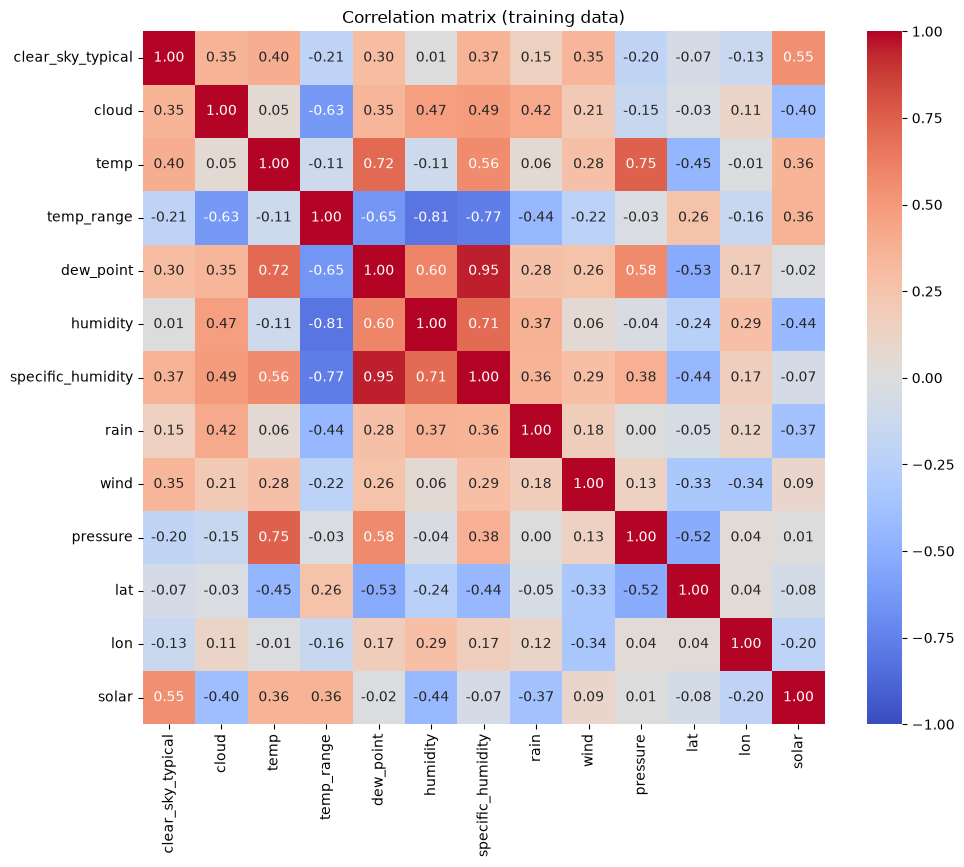

In [37]:
plt.figure(figsize=(11, 9))
sns.heatmap(data.loc[train, features + ["solar"]].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation matrix (training data)")
plt.show()

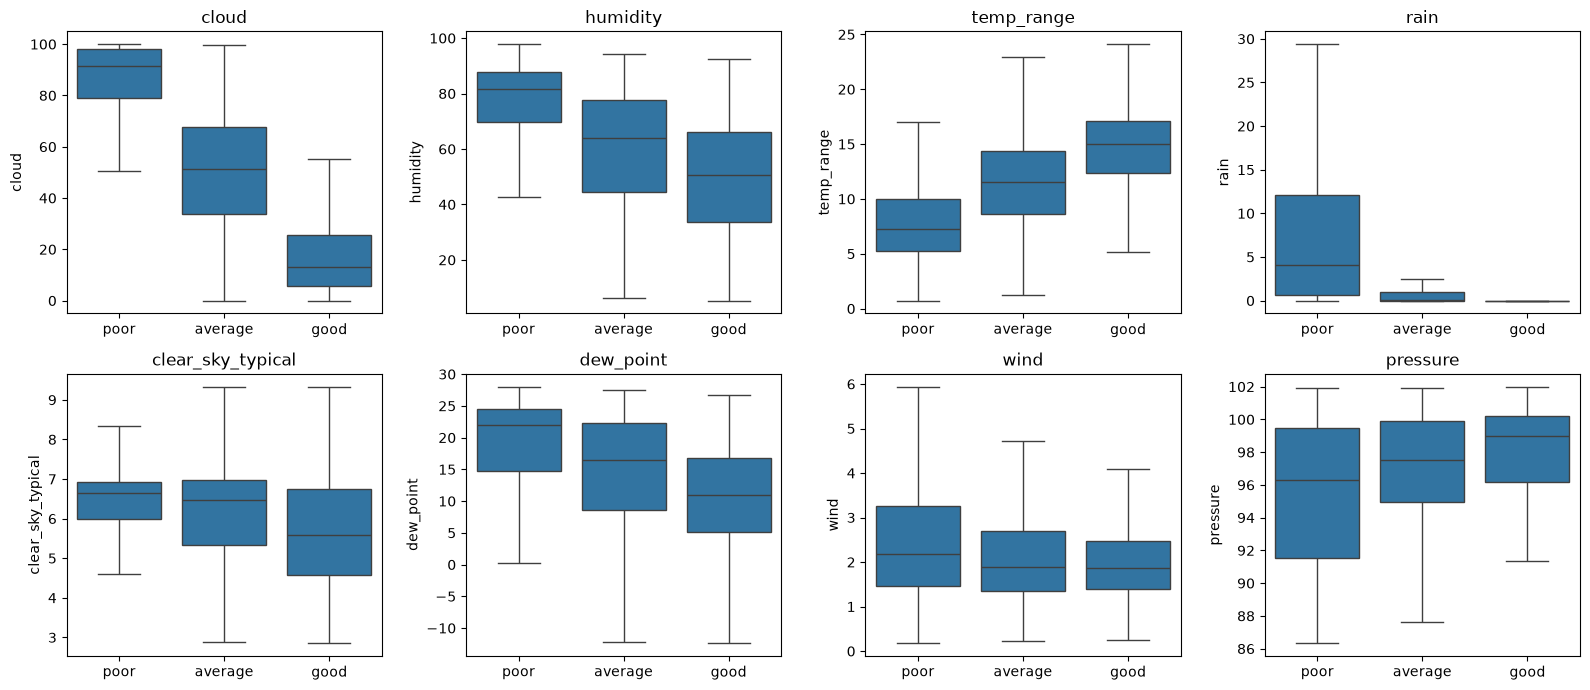

In [38]:
fig = plt.figure(figsize=(16, 7))
for i, col in enumerate(["cloud", "humidity", "temp_range", "rain", "clear_sky_typical", "dew_point", "wind", "pressure"]):
    ax = fig.add_subplot(2, 4, i + 1)
    sns.boxplot(x=data.loc[train, "day_class"].map(dict(enumerate(class_names))), y=data.loc[train, col],
                order=class_names, ax=ax, showfliers=False)
    ax.set_xlabel("")
    ax.set_title(col)
plt.tight_layout()
plt.show()

In [ ]:
profile = data[train].groupby(["city", "month"])["solar"].mean().unstack()
region = data.groupby("city")["region"].first()

pca_city = PCA(2)
Z = pca_city.fit_transform(profile - profile.mean())
print("Variance explained by 2 components:", pca_city.explained_variance_ratio_.round(3))

Variance explained by 2 components: [0.492 0.321]


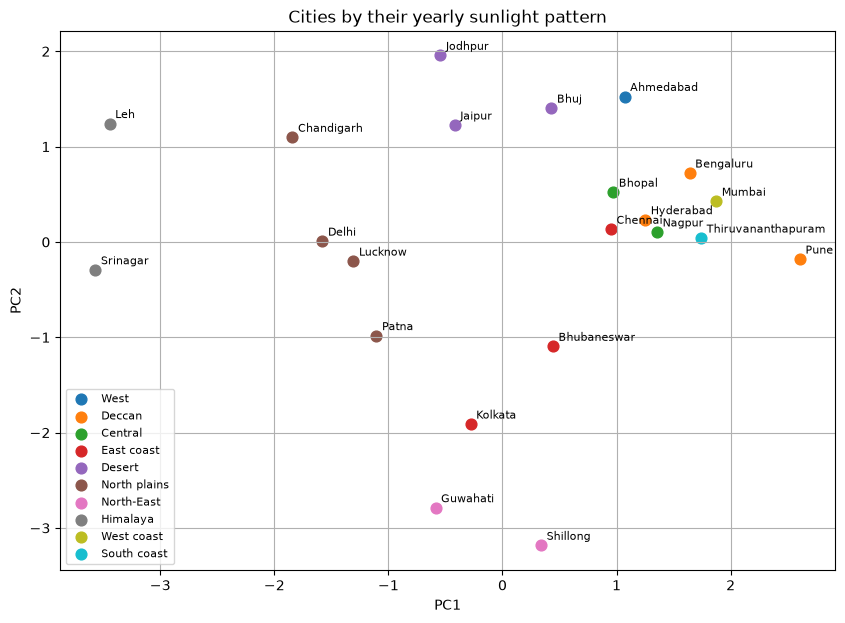

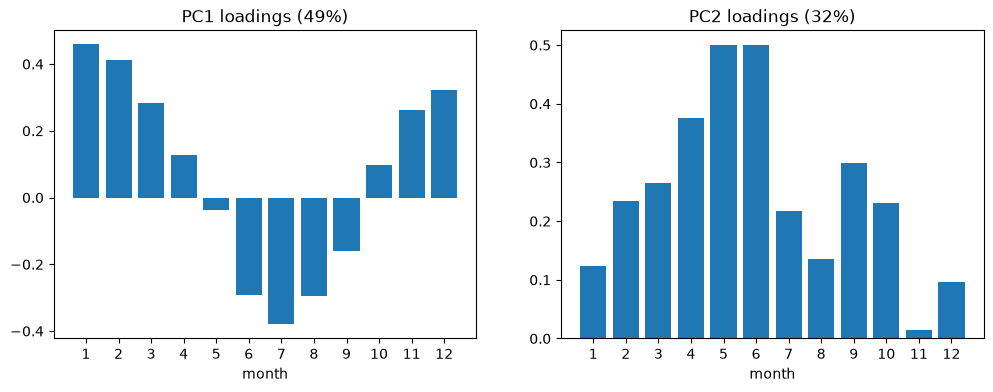

In [40]:
plt.figure(figsize=(10, 7))
for r in region.unique():
    rows = (region[profile.index] == r).values
    plt.scatter(Z[rows, 0], Z[rows, 1], s=60, label=r)
for name, (x, y) in zip(profile.index, Z):
    plt.annotate(name, (x, y), fontsize=8, xytext=(4, 4), textcoords="offset points")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.legend(fontsize=8)
plt.title("Cities by their yearly sunlight pattern")
plt.grid()
plt.show()

fig = plt.figure(figsize=(12, 4))
for i in range(2):
    ax = fig.add_subplot(1, 2, i + 1)
    ax.bar(range(1, 13), pca_city.components_[i])
    ax.set_xticks(range(1, 13))
    ax.set_xlabel("month")
    ax.set_title(f"PC{i+1} loadings ({pca_city.explained_variance_ratio_[i]:.0%})")
plt.show()

In [41]:
scaler = StandardScaler()
X_train = scaler.fit_transform(data.loc[train, features])
X_val = scaler.transform(data.loc[val, features])
X_test = scaler.transform(data.loc[test, features])
y_train, y_val, y_test = data.loc[train, "solar"], data.loc[val, "solar"], data.loc[test, "solar"]

def reg_scores(y_true, pred):
    return {"MAE": mean_absolute_error(y_true, pred), "RMSE": np.sqrt(mean_squared_error(y_true, pred)), "R2": r2_score(y_true, pred)}

print(X_train.shape)

(77044, 12)


clear_sky_typical    1.044
cloud               -0.771
temp                 0.228
temp_range           0.147
dew_point           -0.517
humidity            -0.142
specific_humidity    0.569
rain                -0.331
wind                -0.087
pressure            -0.034
lat                 -0.120
lon                 -0.004
dtype: float64


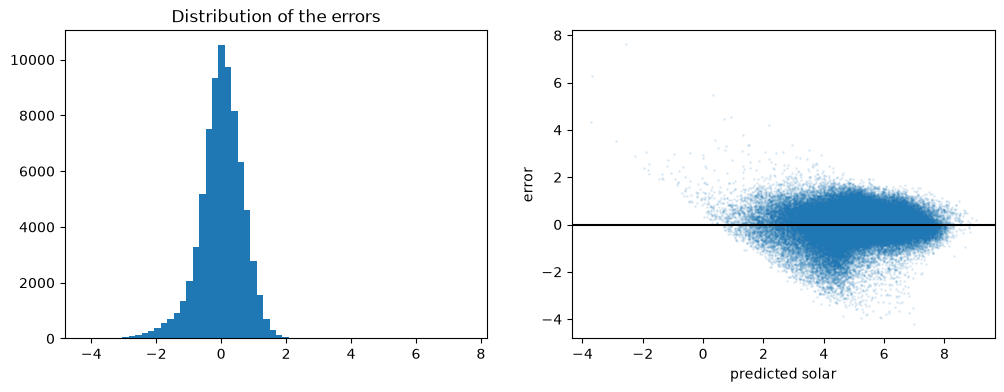

In [ ]:
linear = LinearRegression().fit(X_train, y_train)
print(pd.Series(linear.coef_, index=features).round(3))

error = y_train - linear.predict(X_train)
fig = plt.figure(figsize=(12, 4))
ax = fig.add_subplot(1, 2, 1)
ax.hist(error, bins=60)
ax.set_title("Distribution of the errors")
ax = fig.add_subplot(1, 2, 2)
ax.scatter(linear.predict(X_train), error, s=1, alpha=0.1)
ax.axhline(0, color="k")
ax.set_xlabel("predicted solar")
ax.set_ylabel("error")
plt.show()

In [ ]:
nn_reg = Sequential()
nn_reg.add(Dense(64, input_dim=X_train.shape[1], activation="relu", kernel_regularizer=l2(0.0001)))
nn_reg.add(Dropout(0.1))
nn_reg.add(Dense(32, activation="relu", kernel_regularizer=l2(0.0001)))
nn_reg.add(Dense(16, activation="relu"))
nn_reg.add(Dense(1))
nn_reg.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001), loss="mse", metrics=["mae"])

early_stopping = tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)

history = nn_reg.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=200, batch_size=128, callbacks=[early_stopping], verbose=0)

print("Stopped after", len(history.history["loss"]), "epochs")

/Users/krishkalsi/Desktop/solar-india/venv/lib/python3.13/site-packages/keras/src/layers/core/dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Stopped after 71 epochs


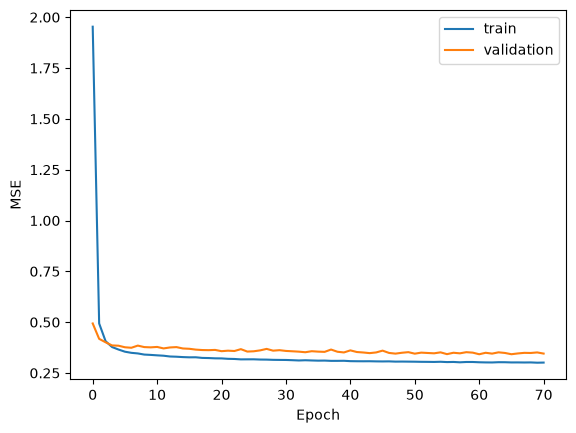

In [44]:
plt.plot(history.history["loss"], label="train")
plt.plot(history.history["val_loss"], label="validation")
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.legend()
plt.show()

In [45]:
reg_val = {
    "Baseline (training mean)": reg_scores(y_val, np.full(len(y_val), y_train.mean())),
    "Linear regression": reg_scores(y_val, linear.predict(X_val)),
    "Neural network": reg_scores(y_val, nn_reg.predict(X_val, verbose=0).ravel()),
}
pd.DataFrame(reg_val).T.round(3)

,MAE,RMSE,R2
Baseline (training mean),1.192,1.482,-0.018
Linear regression,0.540,0.731,0.752
Neural network,0.429,0.579,0.845


In [46]:
c_train, c_val, c_test = data.loc[train, "day_class"].values, data.loc[val, "day_class"].values, data.loc[test, "day_class"].values

def cls_scores(y_true, pred):
    return {"accuracy": accuracy_score(y_true, pred),
            "precision": precision_score(y_true, pred, average="macro"),
            "recall": recall_score(y_true, pred, average="macro"),
            "F1": f1_score(y_true, pred, average="macro")}

logistic = LogisticRegression(max_iter=2000).fit(X_train, c_train)
print("Logistic regression:", {k: round(v, 3) for k, v in cls_scores(c_val, logistic.predict(X_val)).items()})

Logistic regression: {'accuracy': 0.802, 'precision': 0.796, 'recall': 0.799, 'F1': 0.797}


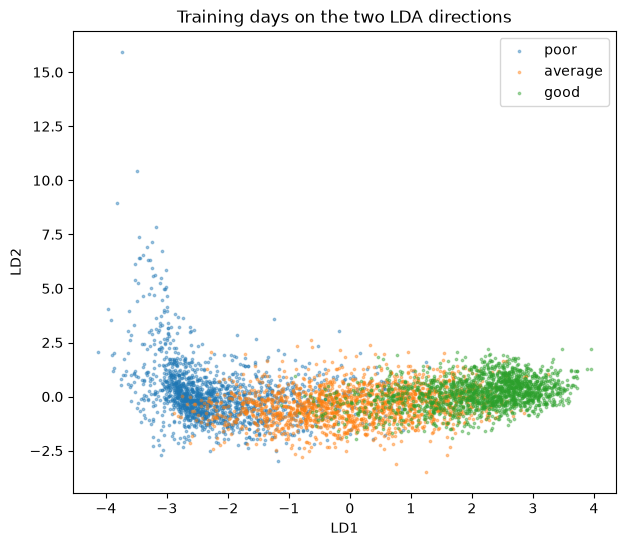

LDA: {'accuracy': 0.79, 'precision': 0.781, 'recall': 0.786, 'F1': 0.781}


In [ ]:
lda = LDA()
lda.fit(X_train, c_train)
X_lda = lda.transform(X_train)

plt.figure(figsize=(7, 6))
sample = np.random.default_rng(0).choice(len(X_lda), 5000, replace=False)
for k, name in enumerate(class_names):
    rows = sample[c_train[sample] == k]
    plt.scatter(X_lda[rows, 0], X_lda[rows, 1], s=3, alpha=0.4, label=name)
plt.xlabel("LD1")
plt.ylabel("LD2")
plt.legend()
plt.title("Training days on the two LDA directions")
plt.show()
print("LDA:", {k: round(v, 3) for k, v in cls_scores(c_val, lda.predict(X_val)).items()})

In [48]:
for k in [5, 25, 75]:
    knn = KNeighborsClassifier(n_neighbors=k).fit(X_train, c_train)
    print(f"KNN k={k:<3}", {m: round(v, 3) for m, v in cls_scores(c_val, knn.predict(X_val)).items()})

KNN k=5   {'accuracy': 0.798, 'precision': 0.793, 'recall': 0.795, 'F1': 0.794}
KNN k=25  {'accuracy': 0.813, 'precision': 0.809, 'recall': 0.81, 'F1': 0.81}
KNN k=75  {'accuracy': 0.811, 'precision': 0.807, 'recall': 0.809, 'F1': 0.808}


In [ ]:
sub = np.random.default_rng(0).choice(train.sum(), 10000, replace=False)
for C in [1, 10]:
    svc = SVC(kernel="rbf", C=C).fit(X_train[sub], c_train[sub])
    print(f"SVM rbf C={C:<3}", {m: round(v, 3) for m, v in cls_scores(c_val, svc.predict(X_val)).items()})

SVM rbf C=1   {'accuracy': 0.809, 'precision': 0.806, 'recall': 0.807, 'F1': 0.806}
SVM rbf C=10  {'accuracy': 0.814, 'precision': 0.812, 'recall': 0.812, 'F1': 0.811}


In [50]:
knn = KNeighborsClassifier(n_neighbors=25).fit(X_train, c_train)
svm = SVC(kernel="rbf", C=10).fit(X_train[sub], c_train[sub])

cls_val = {
    "Baseline (always 'good')": cls_scores(c_val, np.full(len(c_val), 2)),
    "Logistic regression": cls_scores(c_val, logistic.predict(X_val)),
    "LDA": cls_scores(c_val, lda.predict(X_val)),
    "KNN (k=25)": cls_scores(c_val, knn.predict(X_val)),
    "SVM rbf (C=10)": cls_scores(c_val, svm.predict(X_val)),
}
pd.DataFrame(cls_val).T.round(3)

/Users/krishkalsi/Desktop/solar-india/venv/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


,accuracy,precision,recall,F1
Baseline (always 'good'),0.310,0.103,0.333,0.158
Logistic regression,0.802,0.796,0.799,0.797
LDA,0.790,0.781,0.786,0.781
KNN (k=25),0.813,0.809,0.810,0.810
SVM rbf (C=10),0.814,0.812,0.812,0.811


## 6. Final test on the most recent 12 months (run once)

In [51]:
print(f"Test period: {data.loc[test, 'date'].min():%d %b %Y} to {data.loc[test, 'date'].max():%d %b %Y}")

reg_test = {
    "Baseline (training mean)": reg_scores(y_test, np.full(len(y_test), y_train.mean())),
    "Linear regression": reg_scores(y_test, linear.predict(X_test)),
    "Neural network": reg_scores(y_test, nn_reg.predict(X_test, verbose=0).ravel()),
}
pd.DataFrame(reg_test).T.round(3)

Test period: 03 Aug 2025 to 02 Aug 2026


,MAE,RMSE,R2
Baseline (training mean),1.184,1.483,-0.011
Linear regression,0.553,0.745,0.745
Neural network,0.449,0.612,0.828


In [52]:
cls_test = {
    "Baseline (always 'good')": cls_scores(c_test, np.full(len(c_test), 2)),
    "Logistic regression": cls_scores(c_test, logistic.predict(X_test)),
    "LDA": cls_scores(c_test, lda.predict(X_test)),
    "KNN (k=25)": cls_scores(c_test, knn.predict(X_test)),
    "SVM rbf (C=10)": cls_scores(c_test, svm.predict(X_test)),
}
pd.DataFrame(cls_test).T.round(3)

/Users/krishkalsi/Desktop/solar-india/venv/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


,accuracy,precision,recall,F1
Baseline (always 'good'),0.320,0.107,0.333,0.162
Logistic regression,0.797,0.793,0.796,0.794
LDA,0.790,0.785,0.789,0.785
KNN (k=25),0.815,0.813,0.814,0.813
SVM rbf (C=10),0.810,0.809,0.810,0.809


SVM rbf (C=10) on the test year

              precision    recall  f1-score   support

        poor       0.89      0.85      0.87      2838
     average       0.71      0.71      0.71      2621
        good       0.83      0.87      0.85      2571

    accuracy                           0.81      8030
   macro avg       0.81      0.81      0.81      8030
weighted avg       0.81      0.81      0.81      8030



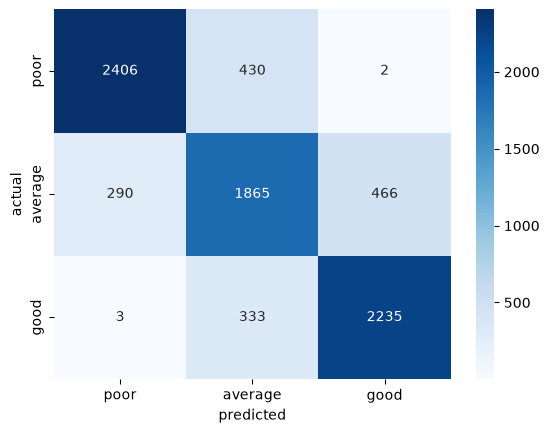

In [53]:
pred = svm.predict(X_test)
print("SVM rbf (C=10) on the test year\n")
print(classification_report(c_test, pred, target_names=class_names))

cm = confusion_matrix(c_test, pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names)
plt.xlabel("predicted")
plt.ylabel("actual")
plt.show()

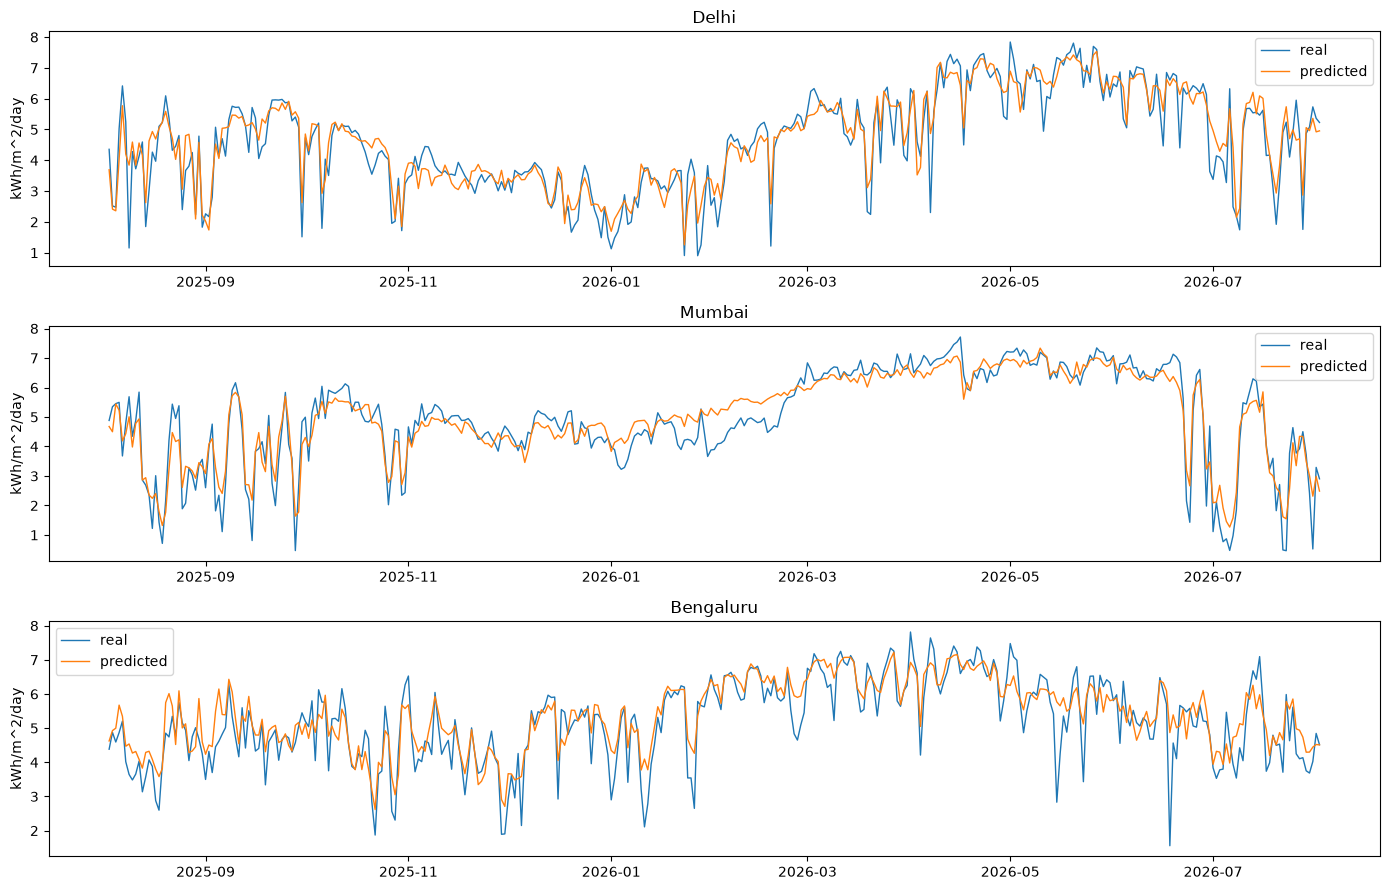

In [ ]:
data.loc[test, "solar_pred"] = nn_reg.predict(X_test, verbose=0).ravel()
fig = plt.figure(figsize=(14, 9))
for i, city in enumerate(["Delhi", "Mumbai", "Bengaluru"]):
    ax = fig.add_subplot(3, 1, i + 1)
    rows = test & (data["city"] == city).values
    ax.plot(data.loc[rows, "date"], data.loc[rows, "solar"], label="real", lw=1)
    ax.plot(data.loc[rows, "date"], data.loc[rows, "solar_pred"], label="predicted", lw=1)
    ax.set_title(city)
    ax.set_ylabel("kWh/m^2/day")
    ax.legend()
plt.tight_layout()
plt.show()

In [55]:
joblib.dump(scaler, MODEL_DIR / "scaler.joblib")
joblib.dump(svm, MODEL_DIR / "svm.joblib")
nn_reg.save(MODEL_DIR / "nn_regression.keras")
typical.to_csv(MODEL_DIR / "clear_sky_typical.csv", index=False)
data.groupby("city")[["lat", "lon", "region"]].first().to_csv(MODEL_DIR / "cities.csv")

meta = {"features": features, "class_names": class_names, "class_cuts": [float(cut_low), float(cut_high)],
        "regression_val": reg_val, "regression_test": reg_test, "classification_val": cls_val, "classification_test": cls_test}
(MODEL_DIR / "meta.json").write_text(json.dumps(meta, indent=2, default=float))

for f in sorted(MODEL_DIR.iterdir()):
    print(f"{f.name:<24} {f.stat().st_size / 1e6:.2f} MB")

cities.csv               0.00 MB
classification_models.joblib 20.23 MB
clear_sky_typical.csv    0.21 MB
meta.json                0.00 MB
nn_classification.keras  0.08 MB
nn_regression.keras      0.07 MB
regression_models.joblib 0.01 MB
scaler.joblib            0.00 MB
svm.joblib               0.61 MB
